# Group B – K-Nearest Neighbours (KNN)
## Diagnosing breast tumours as malignant or benign

**Dataset:** *Breast Cancer Wisconsin (Diagnostic)*, included with scikit-learn. There are 569 tumour samples, and each
has 30 measurements taken from a digitised image of cells (radius, texture, smoothness, concavity, ...). Each sample
is labelled **malignant** (cancerous) or **benign**.

**Question:** Given the measurements of a new tumour, can we predict whether it is malignant by looking at the
most similar tumours we have already diagnosed?

The class example used KNN to *estimate a movie rating* with a hand-written distance function. Here I use KNN for
**classification**. I also look at how to **choose K** properly and why **feature scaling** matters so much.

### How KNN works
KNN has **no real training step**. It just stores all the labelled examples. To classify a new point:
1. Measure the **distance** from the new point to every stored point. Here that is Euclidean distance across all 30 features: $d = \sqrt{\sum_i (a_i - b_i)^2}$
2. Pick the **K closest** points (the "nearest neighbours")
3. The neighbours **vote**, and the new point gets the majority class

Two important points:
* **K** controls the trade-off. A small K (like 1) reacts to every noisy point (overfitting). A very large K blurs everything towards the majority class (underfitting).
* Because it is based on distance, **features must be on the same scale**. Otherwise the feature with the biggest numbers decides the distance.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

### 1. Load the data

In [2]:
cancer = load_breast_cancer()
X = pd.DataFrame(cancer.data, columns=cancer.feature_names)
y = cancer.target                     # 0 = malignant, 1 = benign
labels = cancer.target_names

print(X.shape)
print(pd.Series(y).map(dict(enumerate(labels))).value_counts())
X[["mean radius", "mean texture", "mean area", "mean smoothness"]].describe().round(2)

(569, 30)
benign       357
malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean area,mean smoothness
count,569.00,569.00,569.00,569.00
mean,14.13,19.29,654.89,0.10
std,3.52,4.30,351.91,0.01
min,6.98,9.71,143.50,0.05
25%,11.70,16.17,420.30,0.09
50%,13.37,18.84,551.10,0.10
75%,15.78,21.80,782.70,0.11
max,28.11,39.28,2501.00,0.16


Look at the scales: **mean area** is in the hundreds or thousands, while **mean smoothness** is around 0.1.
Without scaling, a difference of 100 in area would completely outweigh any difference in smoothness when computing distance.

In [3]:
# Hold back 25% of tumours as a test set; stratify keeps the same malignant/benign ratio in both parts
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print(f"Training: {len(X_train)} tumours, Test: {len(X_test)} tumours")

Training: 426 tumours, Test: 143 tumours


### 2. Why scaling matters
I compare KNN (K=5) on the raw measurements with KNN on **standardised** measurements, where each feature is
rescaled to mean 0 and standard deviation 1.

In [4]:
raw_knn = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
scaled_knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(X_train, y_train)

print(f"Without scaling: {accuracy_score(y_test, raw_knn.predict(X_test)):.3f}")
print(f"With scaling:    {accuracy_score(y_test, scaled_knn.predict(X_test)):.3f}")

Without scaling: 0.930
With scaling:    0.979


Scaling improves accuracy from about **93% to 98%** with the same algorithm and the same K. The only change is
that every feature now gets a fair say in the distance.
The scaler is placed in a **pipeline** so it learns the mean and standard deviation from the training data only.

### 3. Choosing K
I can't pick K using the test set, because that would be cheating. Instead I use **5-fold cross-validation**
on the training data. The training set is split into 5 parts, and each part takes a turn as a mini test set.

Best K = 9  (cross-validated accuracy 0.967)


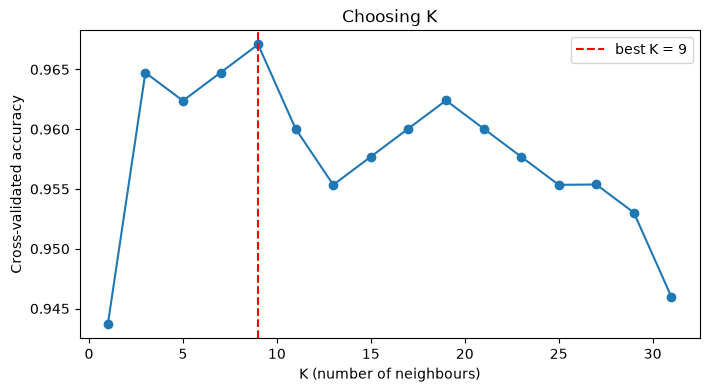

In [5]:
k_values = range(1, 32, 2)     # odd numbers only, so a two-class vote can never be a tie
cv_scores = []
for k in k_values:
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    cv_scores.append(cross_val_score(model, X_train, y_train, cv=5).mean())

best_k = list(k_values)[int(np.argmax(cv_scores))]
print(f"Best K = {best_k}  (cross-validated accuracy {max(cv_scores):.3f})")

plt.figure(figsize=(8, 4))
plt.plot(k_values, cv_scores, "o-")
plt.axvline(best_k, color="red", ls="--", label=f"best K = {best_k}")
plt.xlabel("K (number of neighbours)"); plt.ylabel("Cross-validated accuracy")
plt.title("Choosing K"); plt.legend()
plt.show()

* **K = 1** is the worst. Each prediction copies the single closest tumour, so one unusual neighbour can cause a wrong diagnosis (overfitting).
* Accuracy rises and peaks around **K ≈ 9**, where enough neighbours vote to cancel out noise.
* As K grows larger, accuracy slowly drops, because the vote includes tumours that aren't really similar (underfitting).

### 4. Final model on the unseen test set

Test accuracy with K=9: 0.965

              precision    recall  f1-score   support

   malignant       1.00      0.91      0.95        53
      benign       0.95      1.00      0.97        90

    accuracy                           0.97       143
   macro avg       0.97      0.95      0.96       143
weighted avg       0.97      0.97      0.96       143



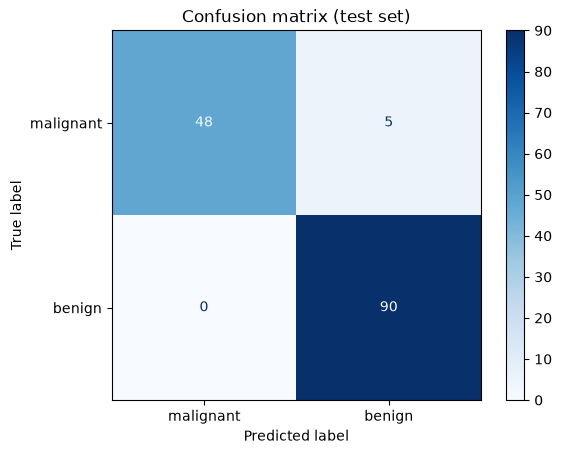

In [6]:
knn_model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k)).fit(X_train, y_train)
y_pred = knn_model.predict(X_test)

print(f"Test accuracy with K={best_k}: {accuracy_score(y_test, y_pred):.3f}\n")
print(classification_report(y_test, y_pred, target_names=labels))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=labels).plot(cmap="Blues")
plt.title("Confusion matrix (test set)")
plt.show()

The **confusion matrix** shows which mistakes the model makes. Rows are the true diagnosis and columns are the prediction.
In a medical setting the most dangerous error is a **malignant tumour predicted as benign** (a missed cancer), so that
cell (top right) is the one to watch, not just the overall accuracy.

Here, every tumour the model calls *malignant* really is malignant (precision 1.00). But it misses 5 of the 53 malignant
tumours (recall 0.91). Note that test accuracy with K = 9 (96.5%) is a little lower than K = 5 gave earlier (97.9%).
With only 143 test tumours, that is a difference of 2 tumours, so it is within normal variation. K = 9 is still the
fairer choice because it was picked by cross-validation, not by looking at the test set.

### 5. Looking inside a prediction
To show exactly what KNN does, I take one test tumour and find its K nearest neighbours by hand.

In [7]:
scaler = knn_model.named_steps["standardscaler"]
X_train_scaled = scaler.transform(X_train)

patient = X_test.iloc[[0]]                       # the first tumour in the test set
patient_scaled = scaler.transform(patient)

# Euclidean distance from this tumour to every training tumour
distances = np.sqrt(((X_train_scaled - patient_scaled) ** 2).sum(axis=1))
nearest = np.argsort(distances)[:best_k]

neighbours = pd.DataFrame({
    "distance": distances[nearest].round(2),
    "diagnosis": labels[y_train[nearest]],
    "mean radius": X_train.iloc[nearest]["mean radius"].values,
    "mean concavity": X_train.iloc[nearest]["mean concavity"].values.round(3),
})
print(f"Test tumour: mean radius {patient['mean radius'].iloc[0]}, mean concavity {patient['mean concavity'].iloc[0]:.3f}")
print(f"True diagnosis: {labels[y_test[0]]}\n")
print(neighbours.to_string(index=False))
print("\nVotes:", neighbours["diagnosis"].value_counts().to_dict())
print("KNN prediction:", labels[knn_model.predict(patient)[0]])

Test tumour: mean radius 12.75, mean concavity 0.039
True diagnosis: benign

 distance diagnosis  mean radius  mean concavity
     1.98    benign        12.54           0.059
     2.15    benign        11.52           0.043
     2.19    benign        13.56           0.079
     2.21    benign        11.61           0.071
     2.23    benign        12.10           0.048
     2.26    benign        12.19           0.029
     2.32    benign        11.27           0.079
     2.35    benign        11.34           0.043
     2.47    benign        11.49           0.053

Votes: {'benign': 9}
KNN prediction: benign


The table above is the whole algorithm: the tumour's closest neighbours are listed by distance, they vote, and the
majority class becomes the diagnosis. My hand-calculated vote matches scikit-learn's prediction.

### Conclusion
* KNN correctly diagnoses about **96–98%** of tumours it has never seen. It does this just by comparing each tumour with the most similar past cases.
* **Feature scaling** made a large difference (about 93% → 98%) because KNN is based entirely on distance.
* **K** was chosen with cross-validation. Very small K overfits, very large K underfits, and K ≈ 9 works best here.
* Limitations: prediction is slow on big datasets, because every new point must be compared with every stored point. In a real medical
  setting, missed cancers (false "benign" predictions) matter more than overall accuracy.